In [46]:
%pip install numpy pandas matplotlib seaborn wfdb

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [47]:
from pathlib import Path
import pandas as pd
import numpy as np
import wfdb
import ast
import matplotlib.pyplot as plt
%matplotlib inline
DATA_ROOT = Path("data/ptbxl")
df = pd.read_csv(DATA_ROOT / "ptbxl_database.csv")

Sampling frequency: 100 Hz
Number of channels: 12
Channel names: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Signal shape: (1000, 12)


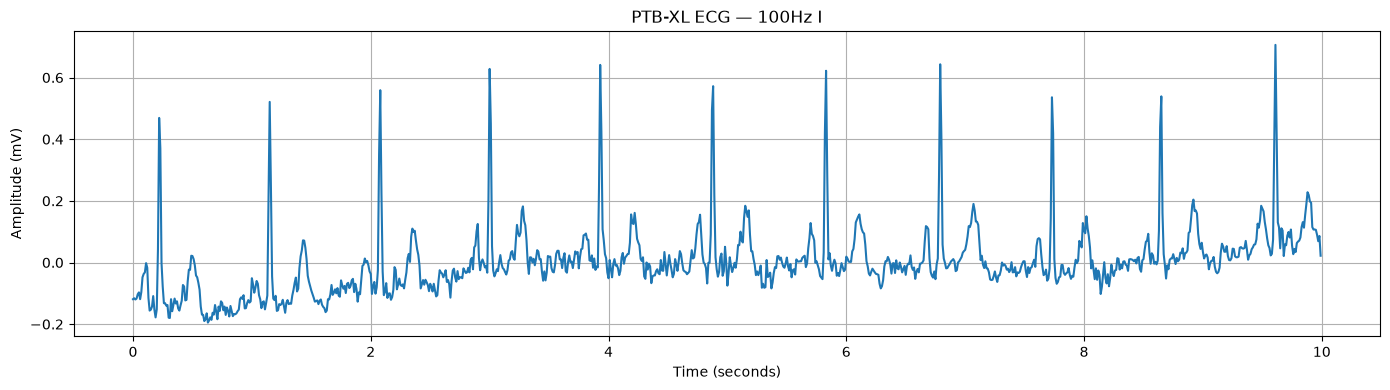

In [48]:


# Path to one PTB-XL recording, without .hea or .dat
record_path = "data/ptbxl/records100/00000/00001_lr"

# Load ECG
record = wfdb.rdrecord(record_path)

print("Sampling frequency:", record.fs, "Hz")
print("Number of channels:", record.n_sig)
print("Channel names:", record.sig_name)
print("Signal shape:", record.p_signal.shape)

# Plot the first 10 seconds of the first channel
duration = min(10, len(record.p_signal) / record.fs)
n_samples = int(duration * record.fs)
time = np.arange(n_samples) / record.fs

plt.figure(figsize=(14, 4))
plt.plot(time, record.p_signal[:n_samples, 0])
plt.xlabel("Time (seconds)")
plt.ylabel(f"Amplitude ({record.units[0]})")
plt.title(f"PTB-XL ECG — 100Hz {record.sig_name[0]}")
plt.grid(True)
plt.tight_layout()
plt.show()

Sampling frequency: 500 Hz
Number of channels: 12
Channel names: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Signal shape: (5000, 12)


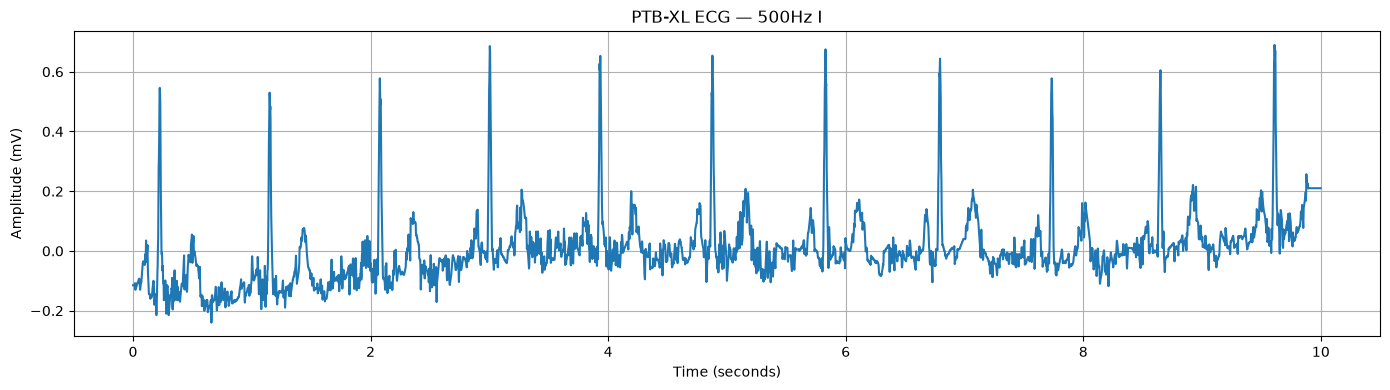

In [49]:


# Path to one PTB-XL recording, without .hea or .dat
record_path = "data/ptbxl/records500/00000/00001_hr"

# Load ECG
record = wfdb.rdrecord(record_path)

print("Sampling frequency:", record.fs, "Hz")
print("Number of channels:", record.n_sig)
print("Channel names:", record.sig_name)
print("Signal shape:", record.p_signal.shape)

# Plot the first 10 seconds of the first channel
duration = min(10, len(record.p_signal) / record.fs)
n_samples = int(duration * record.fs)
time = np.arange(n_samples) / record.fs

plt.figure(figsize=(14, 4))
plt.plot(time, record.p_signal[:n_samples, 0])
plt.xlabel("Time (seconds)")
plt.ylabel(f"Amplitude ({record.units[0]})")
plt.title(f"PTB-XL ECG — 500Hz {record.sig_name[0]}")
plt.grid(True)
plt.tight_layout()
plt.show()

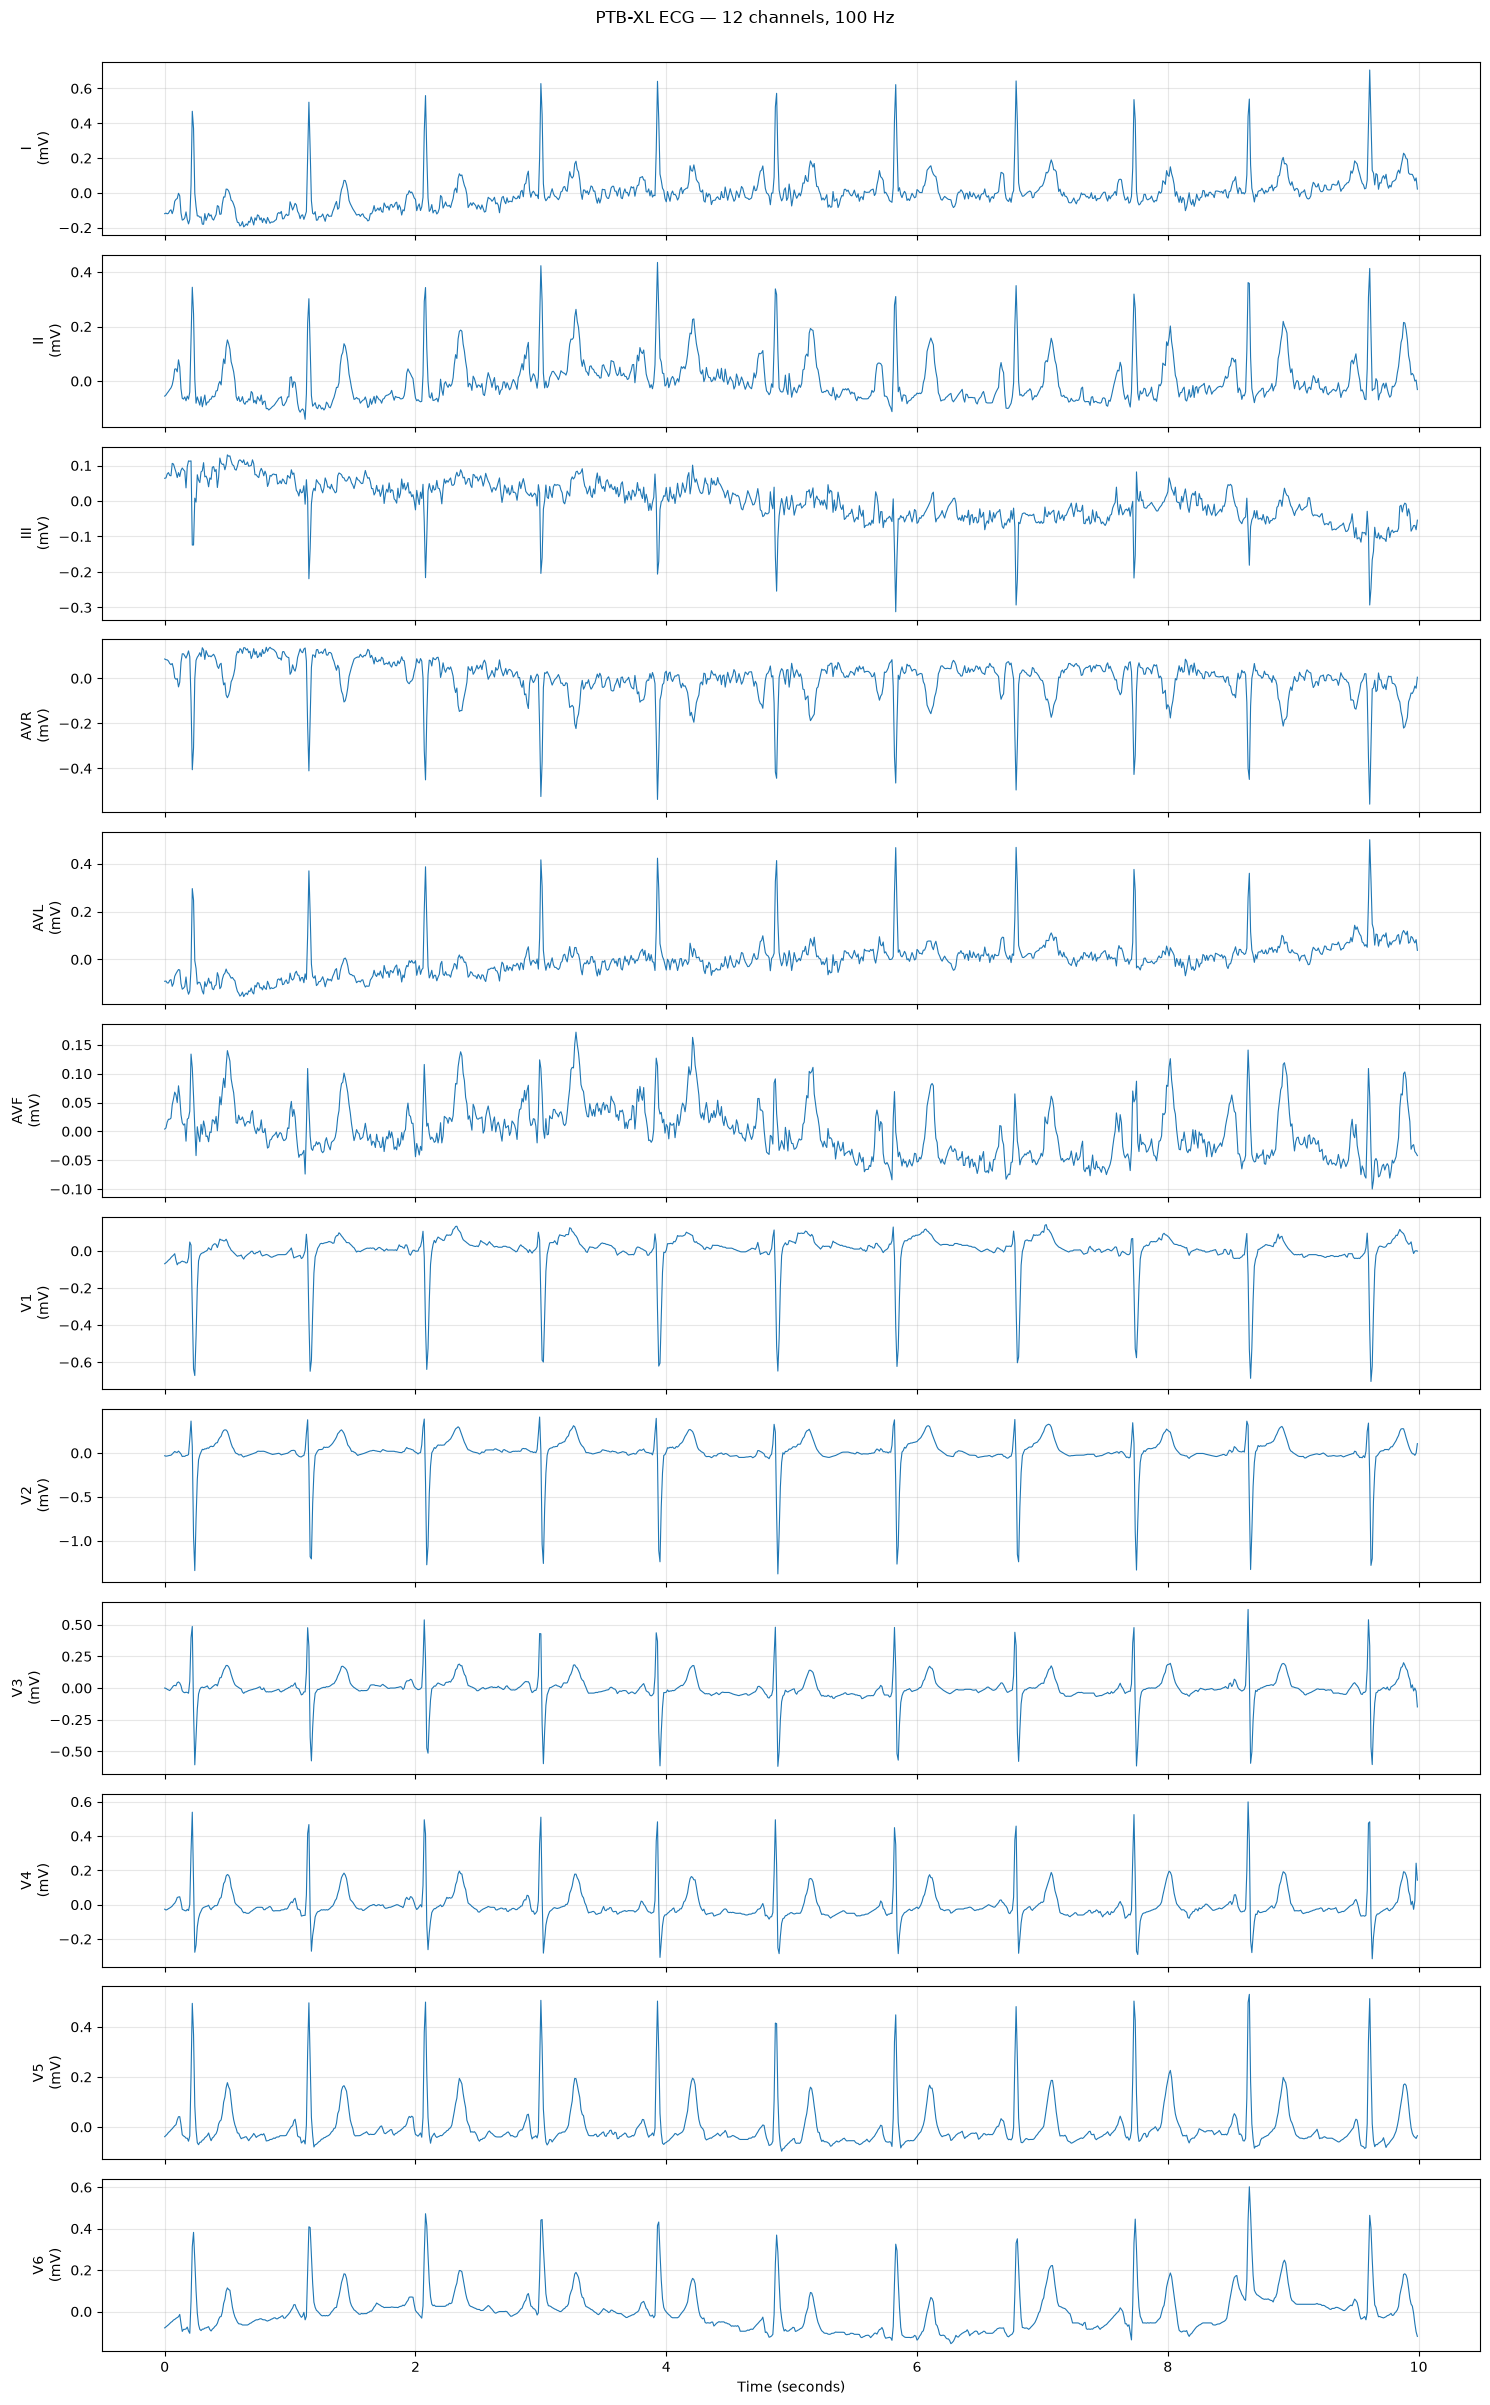

In [50]:


# Path to one PTB-XL recording, without .hea or .dat
record_path = "data/ptbxl/records100/00000/00001_lr"

# Load recording
record = wfdb.rdrecord(record_path)

# Display first 10 seconds
duration = min(10, len(record.p_signal) / record.fs)
n_samples = int(duration * record.fs)
time = np.arange(n_samples) / record.fs

# Create one subplot per ECG channel
fig, axes = plt.subplots(
    record.n_sig, 1,
    figsize=(15, 2 * record.n_sig),
    sharex=True
)

for i, ax in enumerate(axes):
    ax.plot(time, record.p_signal[:n_samples, i], linewidth=0.8)
    ax.set_ylabel(f"{record.sig_name[i]}\n({record.units[i]})")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle(
    f"PTB-XL ECG — {record.n_sig} channels, {record.fs} Hz",
    y=1.0
)

plt.tight_layout()
plt.show()

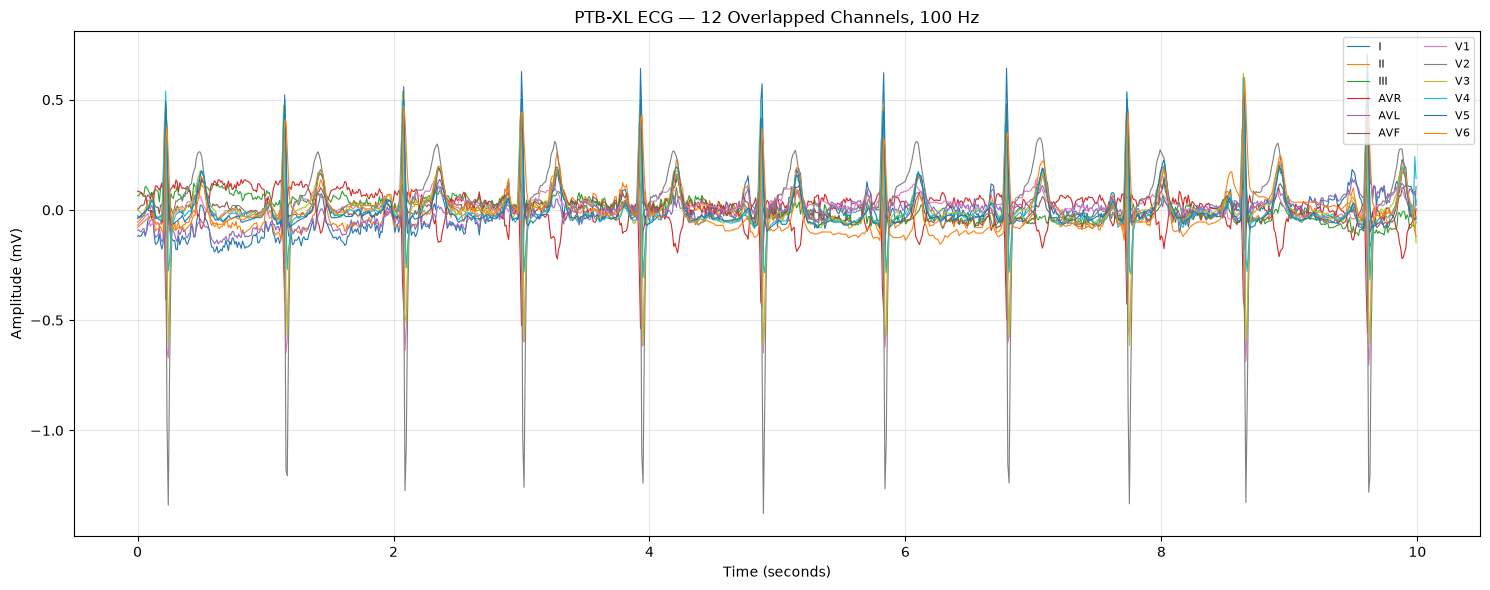

In [51]:
# Path to one PTB-XL recording, without .hea or .dat
record_path = "data/ptbxl/records100/00000/00001_lr"

# Load recording
record = wfdb.rdrecord(record_path)

# Display first 10 seconds
duration = min(10, len(record.p_signal) / record.fs)
n_samples = int(duration * record.fs)
time = np.arange(n_samples) / record.fs

# Plot all ECG channels on the same axes
fig, ax = plt.subplots(figsize=(15, 6))

for i in range(record.n_sig):
    ax.plot(
        time,
        record.p_signal[:n_samples, i],
        linewidth=0.8,
        label=record.sig_name[i]
    )

ax.set_xlabel("Time (seconds)")
ax.set_ylabel(f"Amplitude ({record.units[0]})")
ax.set_title(
    f"PTB-XL ECG — {record.n_sig} Overlapped Channels, {record.fs} Hz"
)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right", ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

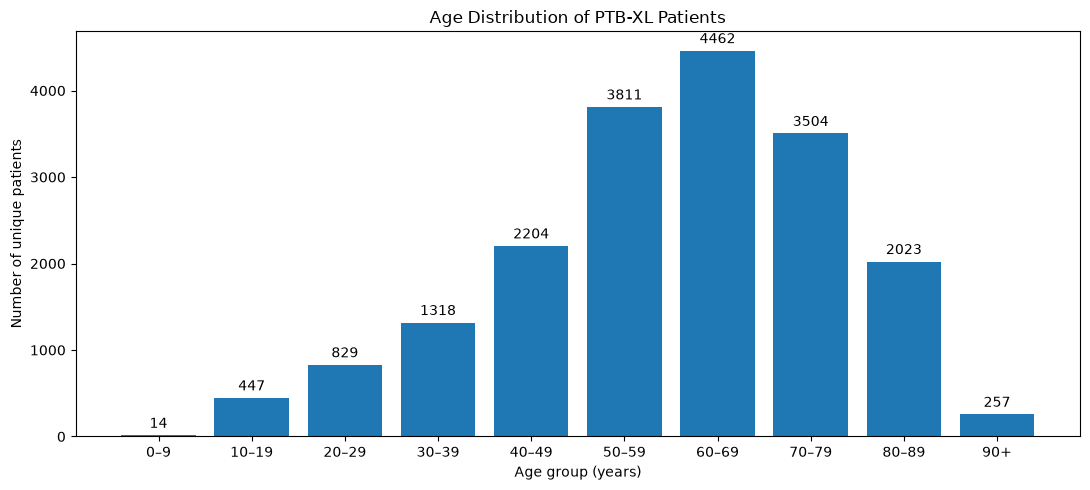

Unique patients: 18,869
Patients with valid ages: 18,869
Patients with missing or invalid ages: 0


In [52]:
# Count each patient only once, even if they have multiple ECG recordings
patients = df.groupby("patient_id", as_index=False)["age"].first()

# Convert ages to numeric and exclude missing or invalid values
patients["age"] = pd.to_numeric(patients["age"], errors="coerce")
ages = patients.loc[patients["age"].between(0, 301), "age"]

# Create age groups
bins = list(range(0, 100, 10)) + [301]
labels = [
    "0–9", "10–19", "20–29", "30–39", "40–49",
    "50–59", "60–69", "70–79", "80–89", "90+"
]

age_groups = pd.cut(
    ages,
    bins=bins,
    labels=labels,
    right=False
)

age_counts = age_groups.value_counts(sort=False)

# Plot the bar graph
plt.figure(figsize=(11, 5))
bars = plt.bar(age_counts.index.astype(str), age_counts.values)

plt.bar_label(bars, padding=3)
plt.title("Age Distribution of PTB-XL Patients")
plt.xlabel("Age group (years)")
plt.ylabel("Number of unique patients")
plt.tight_layout()
plt.show()

print(f"Unique patients: {len(patients):,}")
print(f"Patients with valid ages: {len(ages):,}")
print(f"Patients with missing or invalid ages: {len(patients) - len(ages):,}")



Total ECG recordings: 21799
Recordings without a mapped superclass: 411

Diagnostic superclass distribution:
Category                Meaning  Number of ECGs  Percentage of all ECGs
    NORM             Normal ECG            9514                   43.64
      MI  Myocardial infarction            5469                   25.09
    STTC           ST/T changes            5235                   24.01
      CD Conduction disturbance            4898                   22.47
     HYP            Hypertrophy            2649                   12.15


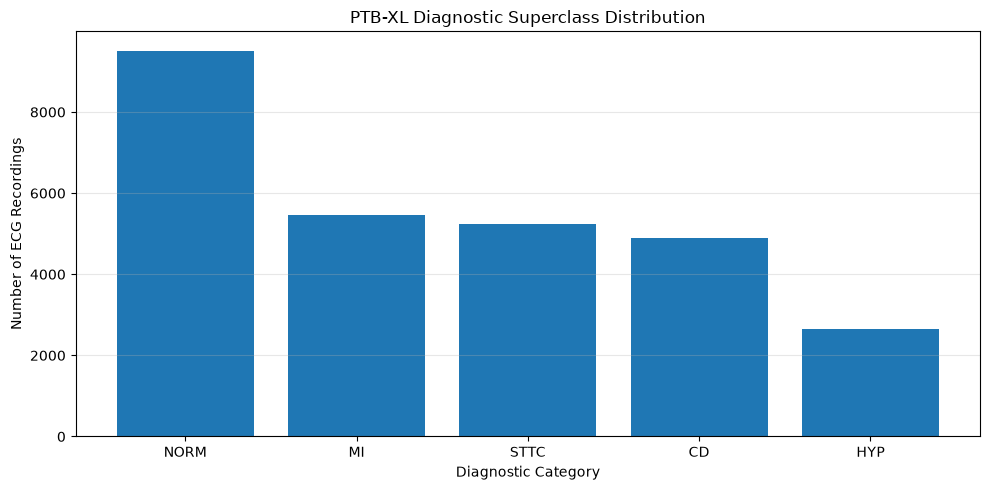

In [53]:
# Load metadata and diagnostic definitions
df = pd.read_csv(DATA_ROOT / "ptbxl_database.csv")
scp = pd.read_csv(DATA_ROOT / "scp_statements.csv", index_col=0)

# Map diagnostic SCP codes to their superclass
scp["diagnostic"] = pd.to_numeric(
    scp["diagnostic"], errors="coerce"
).fillna(0)

code_to_class = (
    scp.loc[scp["diagnostic"] == 1, "diagnostic_class"]
    .dropna()
    .to_dict()
)

descriptions = {
    "NORM": "Normal ECG",
    "MI": "Myocardial infarction",
    "STTC": "ST/T changes",
    "CD": "Conduction disturbance",
    "HYP": "Hypertrophy"
}

# Count each category once per ECG recording
counts = {category: 0 for category in descriptions}
records_without_category = 0

for value in df["scp_codes"]:
    codes = ast.literal_eval(value) if isinstance(value, str) else {}

    categories = {
        code_to_class[code]
        for code in codes
        if code in code_to_class
        and code_to_class[code] in descriptions
    }

    if not categories:
        records_without_category += 1

    for category in categories:
        counts[category] += 1

# Display results
results = pd.DataFrame({
    "Category": list(counts.keys()),
    "Meaning": [descriptions[c] for c in counts],
    "Number of ECGs": list(counts.values())
})

results["Percentage of all ECGs"] = (
    results["Number of ECGs"] / len(df) * 100
).round(2)

print(f"Total ECG recordings: {len(df)}")
print(f"Recordings without a mapped superclass: {records_without_category}")
print("\nDiagnostic superclass distribution:")
print(results.to_string(index=False))

# Plot category distribution
plt.figure(figsize=(10, 5))
plt.bar(results["Category"], results["Number of ECGs"])
plt.title("PTB-XL Diagnostic Superclass Distribution")
plt.xlabel("Diagnostic Category")
plt.ylabel("Number of ECG Recordings")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

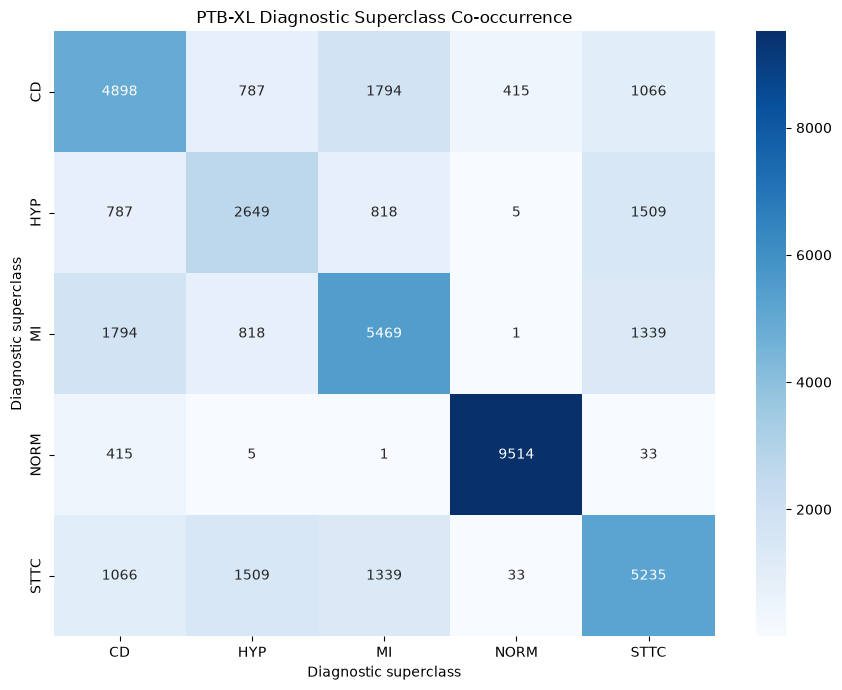

In [54]:
import pandas as pd
import numpy as np
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load PTB-XL metadata
data_dir = "data/ptbxl/"

df = pd.read_csv(data_dir + "ptbxl_database.csv")
scp_statements = pd.read_csv(
    data_dir + "scp_statements.csv", index_col=0
)

# Keep diagnostic SCP statements and map them to diagnostic classes
diagnostic_map = scp_statements.loc[
    scp_statements["diagnostic"].fillna(0).astype(bool),
    "diagnostic_class"
].dropna()

# Extract diagnostic superclasses for every ECG
classes_per_ecg = []

for codes in df["scp_codes"]:
    if isinstance(codes, str):
        codes = ast.literal_eval(codes)

    classes = set()

    for code in codes:
        if code in diagnostic_map.index:
            classes.add(diagnostic_map[code])

    classes_per_ecg.append(classes)

# Create a binary matrix: rows = ECGs, columns = diagnostic classes
all_classes = sorted(set().union(*classes_per_ecg))

Y = pd.DataFrame(
    0,
    index=range(len(classes_per_ecg)),
    columns=all_classes
)

for i, classes in enumerate(classes_per_ecg):
    for cls in classes:
        Y.loc[i, cls] = 1

# Count how often each pair of diagnoses occurs together
cooccurrence = Y.T.dot(Y).astype(int)

# Plot the co-occurrence matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cooccurrence,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("PTB-XL Diagnostic Superclass Co-occurrence")
plt.xlabel("Diagnostic superclass")
plt.ylabel("Diagnostic superclass")
plt.tight_layout()
plt.show()